In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
data = pd.read_csv('./DataSets/income_data.csv')
data

,Unnamed: 0,income,happiness
0,1,3.862647,2.314489
1,2,4.979381,3.433490
2,3,4.923957,4.599373
3,4,3.214372,2.791114
4,5,7.196409,5.596398
...,...,...,...
493,494,5.249209,4.568705
494,495,3.471799,2.535002
495,496,6.087610,4.397451
496,497,3.440847,2.070664


In [9]:
data = data.drop(columns=['Unnamed: 0'])
data

,income,happiness
0,3.862647,2.314489
1,4.979381,3.433490
2,4.923957,4.599373
3,3.214372,2.791114
4,7.196409,5.596398
...,...,...
493,5.249209,4.568705
494,3.471799,2.535002
495,6.087610,4.397451
496,3.440847,2.070664


In [10]:
X = data[['income']]
X

,income
0,3.862647
1,4.979381
2,4.923957
3,3.214372
4,7.196409
...,...
493,5.249209
494,3.471799
495,6.087610
496,3.440847


In [12]:
y = data['happiness']
y

0      2.314489
1      3.433490
2      4.599373
3      2.791114
4      5.596398
         ...   
493    4.568705
494    2.535002
495    4.397451
496    2.070664
497    3.710193
Name: happiness, Length: 498, dtype: float64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [15]:
print('Intercept: ', model.intercept_)
print('Slope: ', model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  0.14170387227353531
Slope:  0.7247687016076183
Actual Values:  [4.75416839 4.1596093  2.29570014 2.31155424 2.86127444 1.96563593
 4.57080113 4.00453774 1.46061633 3.73794161 4.83350643 3.05738784
 3.06760945 2.78424454 2.15584332 2.96216821 2.23344058 6.29910126
 1.83980201 2.96195666 2.33627603 4.2452156  2.11513648 1.30848726
 4.71966533 0.77128657 2.67988732 4.98525493 3.80429886 4.8266027
 0.69845996 3.04079729 2.39167752 4.5993734  3.73056996 3.70343793
 0.96852733 3.45310274 1.41666106 1.41022957 5.83619666 4.3284171
 5.9142477  5.3139569  2.31448898 2.00904646 2.57505486 3.02072445
 2.20098217 0.26604366 3.98112774 3.22747217 5.26547896 4.93304409
 2.66611603 4.30728842 3.99041589 4.56870456 5.68375056 3.94101932
 4.32466038 1.92757883 5.15933124 4.08382116 2.45320906 4.68281699
 4.28430556 4.0564931  2.41338175 4.72098734 4.63344105 2.94753147
 1.77593255 2.20824052 0.54836519 4.21269734 4.25831153 5.03400379
 3.58387516 4.3213643  3.87278885 2.96732327 2.57693996 

In [16]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  0.6269683431894553
MSE:  0.590146394343082
RMSE:  0.768209863476825
R-Squared Error:  0.6662585264303965


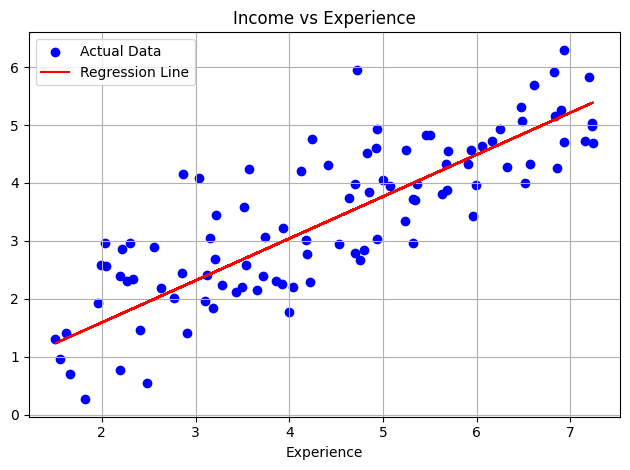

In [17]:
plt.scatter(X_test, y_test, color='blue', label='Actual Data')
plt.plot(X_test, y_pred, color='red', label='Regression Line')

plt.title('Income vs Experience')

plt.legend()
plt.xlabel('Income')
plt.xlabel('Experience')


plt.tight_layout()
plt.grid()
plt.show()

### Ridge

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

In [22]:
model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas = [0.01, 0.1, 1, 10, 100])
)

In [23]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridgecv', RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [25]:
ridge_model = model.named_steps['ridgecv']
print('Best alpha (lambda): ', ridge_model.alpha_)

Best alpha (lambda):  0.1


In [27]:
y_pred = model.predict(X_test)
y_pred

array([3.21757273, 2.21821652, 3.20284987, 1.79060843, 1.7443605 ,
       2.39043787, 4.44637674, 4.85973689, 1.89088328, 3.50453939,
       4.09815433, 2.43210801, 2.85607724, 3.54515187, 2.78811792,
       1.80808564, 2.52145824, 5.16629292, 2.45117981, 3.9962882 ,
       1.83525054, 2.73014538, 2.63154821, 1.23394614, 4.61081417,
       1.72926666, 2.46432418, 5.37779689, 4.21863401, 4.12770819,
       1.34580453, 3.72055472, 2.83559072, 3.71035279, 4.000677  ,
       4.0099718 , 1.27190122, 2.47669815, 1.3191131 , 2.24938703,
       5.35549056, 4.42218783, 5.08889408, 4.83577809, 2.94134209,
       2.15192775, 1.62683344, 3.16877891, 2.6774034 , 1.4644956 ,
       4.02900618, 2.98879779, 5.13994221, 3.71633084, 3.58842177,
       3.34252626, 3.54800114, 3.94602594, 4.9302054 , 3.81943557,
       4.89780966, 1.56016307, 5.09561086, 2.34522063, 2.21372428,
       5.38947804, 4.72204557, 3.76914307, 2.40795691, 5.32597606,
       4.52799403, 3.42735697, 3.04270426, 3.0726687 , 1.94121

In [30]:
print('Intercept: ', ridge_model.intercept_)
print('Slope: ', ridge_model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  3.3881444001909546
Slope:  1.2741061319246618
Actual Values:  [4.75416839 4.1596093  2.29570014 2.31155424 2.86127444 1.96563593
 4.57080113 4.00453774 1.46061633 3.73794161 4.83350643 3.05738784
 3.06760945 2.78424454 2.15584332 2.96216821 2.23344058 6.29910126
 1.83980201 2.96195666 2.33627603 4.2452156  2.11513648 1.30848726
 4.71966533 0.77128657 2.67988732 4.98525493 3.80429886 4.8266027
 0.69845996 3.04079729 2.39167752 4.5993734  3.73056996 3.70343793
 0.96852733 3.45310274 1.41666106 1.41022957 5.83619666 4.3284171
 5.9142477  5.3139569  2.31448898 2.00904646 2.57505486 3.02072445
 2.20098217 0.26604366 3.98112774 3.22747217 5.26547896 4.93304409
 2.66611603 4.30728842 3.99041589 4.56870456 5.68375056 3.94101932
 4.32466038 1.92757883 5.15933124 4.08382116 2.45320906 4.68281699
 4.28430556 4.0564931  2.41338175 4.72098734 4.63344105 2.94753147
 1.77593255 2.20824052 0.54836519 4.21269734 4.25831153 5.03400379
 3.58387516 4.3213643  3.87278885 2.96732327 2.57693996 3

In [31]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  0.6269402572905592
MSE:  0.5900863905372834
RMSE:  0.7681708081782875
R-Squared Error:  0.6662924599742748


### Lasso

In [33]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [34]:
model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas = [0.01, 0.1, 1, 10, 100])
)

In [35]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lassocv', LassoCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [36]:
lasso_model = model.named_steps['lassocv']
print('Best alpha (lambda): ', lasso_model.alpha_)

Best alpha (lambda):  0.01


In [40]:
y_pred = lasso_model.predict(X_test)
y_pred

c:\Users\athre\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:432: UserWarning: X has feature names, but LassoCV was fitted without feature names
  warnings.warn(


array([ 8.7542083 ,  7.01030059,  8.72851645,  6.26411115,  6.18340708,
        7.3108322 , 10.89850956, 11.6198359 ,  6.43909389,  9.25497405,
       10.29085062,  7.3835479 ,  8.12338741,  9.32584411,  8.00479628,
        6.29460943,  7.53946684, 12.15478571,  7.41682878, 10.11309104,
        6.34201302,  7.9036324 ,  7.73157726,  5.29271812, 11.185458  ,
        6.15706786,  7.43976613, 12.52386672, 10.5010914 , 10.34242302,
        5.4879145 ,  9.63192754,  8.08763779,  9.61412485, 10.12074963,
       10.13696935,  5.35895093,  7.46135908,  5.44133713,  7.0646941 ,
       12.48494148, 10.85629916, 12.01972233, 11.57802704,  8.27217723,
        6.89462462,  5.9783187 ,  8.66906157,  7.81159599,  5.69503412,
       10.17018493,  8.35498891, 12.1088029 ,  9.62455674,  9.40135142,
        8.97225611,  9.33081616, 10.02538183, 11.74280564,  9.80447769,
       11.68627406,  5.86197683, 12.03144333,  7.23192671,  7.0024615 ,
       12.54425071, 11.37956026,  9.71671572,  7.34140348, 12.43

In [41]:
print('Intercept: ', ridge_model.intercept_)
print('Slope: ', ridge_model.coef_[0])
print('Actual Values: ', y_test.values)
print('Predicted Values: ', y_pred)

Intercept:  3.3881444001909546
Slope:  1.2741061319246618
Actual Values:  [4.75416839 4.1596093  2.29570014 2.31155424 2.86127444 1.96563593
 4.57080113 4.00453774 1.46061633 3.73794161 4.83350643 3.05738784
 3.06760945 2.78424454 2.15584332 2.96216821 2.23344058 6.29910126
 1.83980201 2.96195666 2.33627603 4.2452156  2.11513648 1.30848726
 4.71966533 0.77128657 2.67988732 4.98525493 3.80429886 4.8266027
 0.69845996 3.04079729 2.39167752 4.5993734  3.73056996 3.70343793
 0.96852733 3.45310274 1.41666106 1.41022957 5.83619666 4.3284171
 5.9142477  5.3139569  2.31448898 2.00904646 2.57505486 3.02072445
 2.20098217 0.26604366 3.98112774 3.22747217 5.26547896 4.93304409
 2.66611603 4.30728842 3.99041589 4.56870456 5.68375056 3.94101932
 4.32466038 1.92757883 5.15933124 4.08382116 2.45320906 4.68281699
 4.28430556 4.0564931  2.41338175 4.72098734 4.63344105 2.94753147
 1.77593255 2.20824052 0.54836519 4.21269734 4.25831153 5.03400379
 3.58387516 4.3213643  3.87278885 2.96732327 2.57693996 3

In [42]:
print('MAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R-Squared Error: ', r2_score(y_test, y_pred))

MAE:  5.562309070802926
MSE:  32.483390609584475
RMSE:  5.699420199422436
R-Squared Error:  -17.37011079369111
